# Exciton–cavity polaritons planar microcavity

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm, TwoSlopeNorm, LogNorm
from matplotlib.lines import Line2D
import matplotlib.tri as mtri
from scipy.signal import find_peaks
import numpy as np
from tqdm.auto import tqdm

import microcavity as mc

plt.rcParams.update({
    "figure.dpi": 120, "axes.grid": True, "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
})
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
FIGURE_WIDTH = 7.2
FIGURE_HEIGHT = 3.2

def save_show(fig, filename, dpi=160):
    fig.savefig(
        FIGURE_DIR / filename, dpi=dpi, bbox_inches="tight",
        facecolor="white", pil_kwargs={"optimize": True, "compress_level": 9},
    )
    plt.show()
    plt.close(fig)

def minimum_energy_bins(energies, values, bins):
    block = len(energies) // bins
    usable = block * bins
    energy_bins = energies[:usable].reshape(bins, block).mean(axis=1)
    value_bins = values[:, :usable].reshape(len(values), bins, block).min(axis=2)
    return energy_bins, value_bins

def save_csv(filename, columns, arrays):
    np.savetxt(
        DATA_DIR / filename, np.column_stack(arrays), delimiter=",",
        header=",".join(columns), comments="",
    )

NUMERICAL_GRID_STYLE = {"marker": ".", "markersize": 2.0}

cfg = {
    "n_air": 1.0,
    "n_h": 3.60,
    "n_l": 2.95,
    "n_cavity": 3.60,
    "n_qw": 3.65,
    "energy_zero": 1.450,
    "n_top": 23,
    "n_bottom": 26,
    "qw_thickness": 0.006,
    "exciton_mass_ratio": 0.5,
    "gamma_x": mc.mev(0.25),
    "single_qw_rabi_target": mc.mev(8.0 / np.sqrt(6.0)),
    "energy_min": 1.35,
    "energy_max": 1.55,
    "energy_points": 4001,
    "momentum_min": 0.0,
    "momentum_max": 4.0,
    "momentum_points": 241,
    "bare_map_points": 120000,
    "polariton_map_points": 60000,
    "map_display_rows": 1200,
    "angle_max_degrees": 30.0,
    "angle_points": 241,
    "field_dz": 5.0e-4,
    "dbr_cases": [(8, 8), (12, 12), (16, 16), (23, 26)],
    "detunings_mev": [-8.0, -5.8, 0.0, 1.0],
    "position_points": 65,
    "tuning_options": {
        "resonance_half_window": 0.03,
        "resonance_coarse_points": 401,
    },
}

## 1. Materials, geometry, and analytical scalar model

In [2]:
cfg["lambda_zero"] = mc.HC / cfg["energy_zero"]
cfg["d_h"] = cfg["lambda_zero"] / (4.0 * cfg["n_h"])
cfg["d_l"] = cfg["lambda_zero"] / (4.0 * cfg["n_l"])
cfg["cavity_length_initial"] = 2.0 * cfg["lambda_zero"] / cfg["n_cavity"]

energy_grid = np.linspace(cfg["energy_min"], cfg["energy_max"], cfg["energy_points"])
momentum_grid = np.linspace(cfg["momentum_min"], cfg["momentum_max"], cfg["momentum_points"])
angle_grid = np.linspace(0.0, cfg["angle_max_degrees"], cfg["angle_points"])
exciton_grid = mc.exciton_energy(momentum_grid, cfg["energy_zero"], cfg["exciton_mass_ratio"])
ideal_photon_grid = mc.photon_energy(momentum_grid, cfg["energy_zero"], cfg["n_cavity"])
analytical_lp, analytical_up = mc.polariton_energies(
    ideal_photon_grid, exciton_grid, cfg["single_qw_rabi_target"]
)
hopfield = mc.hopfield_coefficients(
    ideal_photon_grid, exciton_grid, cfg["single_qw_rabi_target"]
)

print(f"lambda_0 = {cfg['lambda_zero'] * 1e3:.3f} nm")
print(f"d_H = {cfg['d_h'] * 1e3:.3f} nm, d_L = {cfg['d_l'] * 1e3:.3f} nm")
print(f"L_C initial = {cfg['cavity_length_initial']:.6f} um")
print(f"ideal photon mass = {mc.photon_mass_ratio(cfg['energy_zero'], cfg['n_cavity']):.4e} m0")

lambda_0 = 855.063 nm
d_H = 59.379 nm, d_L = 72.463 nm
L_C initial = 0.475035 um
ideal photon mass = 3.6775e-05 m0


In [3]:
energy_offset = lambda values: mc.to_mev(np.asarray(values) - cfg["energy_zero"])
branch_angle = lambda values: mc.external_angle_degrees(
    momentum_grid, values, n_external=cfg["n_air"]
)

# 2. Analytical polariton dispersion at equal k and as angular branch plots
fig, axes = plt.subplots(1, 2, figsize=(10.2, FIGURE_HEIGHT), layout="constrained")
branches = (
    (ideal_photon_grid, "--", "0.5", "bare photon"),
    (exciton_grid, ":", "0.35", "bare exciton"),
    (analytical_lp, "-", "C0", "lower polariton (LP)"),
    (analytical_up, "-", "C1", "upper polariton (UP)"),
)
for values, style, color, label in branches:
    axes[0].plot(momentum_grid, energy_offset(values), style, color=color, label=label)
    axes[1].plot(branch_angle(values), energy_offset(values), style, color=color, label=label)
axes[0].set(xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
            ylabel=r"energy relative to $E_X(0)$ (meV)")
axes[1].set(xlabel=r"external angle $\theta_{\rm ext}$ (degrees)",
            ylabel=r"energy relative to $E_X(0)$ (meV)")
axes[0].legend(title=r"Analytical $2\times2$ model", fontsize=7)
save_show(fig, "02_analytical_polariton_dispersion.png")

# 3. Hopfield coefficients
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, 2.8), sharey=True, layout="constrained")
for ax, branch in zip(axes, ("lp", "up")):
    ax.plot(momentum_grid, hopfield[f"photon_{branch}"], label=r"photon $|C|^2$")
    ax.plot(momentum_grid, hopfield[f"exciton_{branch}"], "--", label=r"exciton $|X|^2$")
    branch_name = "Lower polariton" if branch == "lp" else "Upper polariton"
    ax.set(
        xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
        title=branch_name, ylim=(0, 1),
    )
    ax.legend(title=r"Analytical $2\times2$ model")
axes[0].set_ylabel("Hopfield fraction")
save_show(fig, "03_hopfield_coefficients.png")

/tmp/ipykernel_33825/2471131515.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 2. Exact DBR structure and passive-QW photon reference

The QW position and passive-index tuning form a small fixed-point problem. We first tune a homogeneous cavity, place the QW at its central antinode, and then iterate passive-QW tuning and antinode reconstruction.

In [4]:
base_geometry = {
    "n_h": cfg["n_h"], "n_l": cfg["n_l"],
    "d_h": cfg["d_h"], "d_l": cfg["d_l"],
    "n_top": cfg["n_top"], "n_bottom": cfg["n_bottom"],
    "n_cavity": cfg["n_cavity"],
}

def qw_spec(z, gamma_0=0.0, enabled=False, name="QW"):
    return {
        "name": name, "z": z, "n": cfg["n_qw"],
        "d": cfg["qw_thickness"], "ex0": cfg["energy_zero"],
        "mass_ratio": cfg["exciton_mass_ratio"],
        "gamma_x": cfg["gamma_x"], "gamma_0": gamma_0,
        "enabled": enabled,
    }

def homogeneous_builder(length):
    return mc.build_microcavity(**base_geometry, cavity_length=length)

def background_builder(length, offset):
    return mc.build_microcavity(
        **base_geometry, cavity_length=length,
        qws=[qw_spec(length / 2.0 + offset)],
    )

baseline = mc.tune_qw_to_central_antinode(
    homogeneous_builder, background_builder, cfg["energy_zero"],
    cfg["cavity_length_initial"],
    n_left=cfg["n_air"], n_right=cfg["n_air"],
    minimum_peak_separation=cfg["lambda_zero"] / (4.0 * cfg["n_cavity"]),
    dz=cfg["field_dz"], tuning_options=cfg["tuning_options"],
)
cavity_length = baseline["length"]
qw_offset = baseline["qw_offset"]
qw_position = baseline["qw_position"]
background_layers = baseline["layers"]
print(f"tuned L_C = {cavity_length:.9f} um")
print(f"QW centre = {qw_position:.9f} um, centre offset = {qw_offset * 1e3:.3f} nm")


tuned L_C = 0.474867789 um
QW centre = 0.237416272 um, centre offset = -0.018 nm


In [5]:
exterior_width = 2.0 * (cfg["d_h"] + cfg["d_l"])
z_index, n_index = mc.index_profile(
    background_layers, n_left=cfg["n_air"], n_right=cfg["n_air"],
    exterior_width=exterior_width,
)
field = baseline["field"]
antinodes = mc.find_field_antinodes(
    field["z"], field["intensity"],
    minimum_separation=cfg["lambda_zero"] / (4.0 * cfg["n_cavity"]),
)
# 1. Refractive-index profile
top_dbr_width = mc.total_thickness(background_layers, region="top_dbr")
qw_global_position = top_dbr_width + qw_position
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, 2.8), layout="constrained")
ax.plot(z_index, n_index)
ax.axvspan(
    qw_global_position - cfg["qw_thickness"] / 2.0,
    qw_global_position + cfg["qw_thickness"] / 2.0,
    color="tab:red", alpha=0.35, label="quantum well (QW)",
)
ax.set(
    xlabel=r"position in multilayer stack $z$ ($\mu$m)",
    ylabel=r"refractive index $n(z)$",
    title="Prescribed finite multilayer structure",
)
ax.legend(loc="upper right")
save_show(fig, "01_refractive_index_profile.png")


/tmp/ipykernel_33825/2471131515.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 3. Bare finite-DBR cavity and numerical checks

In [6]:
checks = mc.basic_tmm_checks(
    background_layers, energy_grid,
    n_left=cfg["n_air"], n_right=cfg["n_air"],
    n_test_a=cfg["n_h"], n_test_b=cfg["n_l"],
)
assert checks["zero_thickness_error"] < 1e-14
assert checks["interface_inverse_error"] < 1e-12
assert checks["energy_conservation_error"] < 1e-9
assert checks["normal_incidence_te_tm_error"] < 1e-10
print(checks)

bare_pole = mc.solve_bare_cavity_pole(
    background_layers, cfg["energy_zero"],
    n_left=cfg["n_air"], n_right=cfg["n_air"],
)
print("bare pole:", bare_pole["pole"])
print(f"bare linewidth = {mc.to_mev(mc.linewidth_from_pole(bare_pole['pole'])):.6f} meV")
print(f"bare Q = {mc.quality_factor_from_pole(bare_pole['pole']):.1f}")

bare_poles = np.empty(momentum_grid.shape, dtype=np.complex128)
bare_pole_residuals = np.full(momentum_grid.shape, np.nan)
bare_poles[0] = bare_pole["pole"]
bare_pole_residuals[0] = bare_pole["residual"]
for index, momentum in enumerate(
    tqdm(momentum_grid[1:], desc="bare complex pole"), start=1,
):
    matrix = lambda energy, k=float(momentum): mc.stack_matrix(
        energy, k, "TE", background_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    result = mc.solve_complex_pole(matrix, bare_poles[index - 1])
    if not result["success"]:
        result = mc.solve_bare_cavity_pole(
            background_layers, bare_poles[index - 1].real,
            n_left=cfg["n_air"], n_right=cfg["n_air"],
            polarization="TE", k_parallel=float(momentum),
            minimum_half_window=0.003,
        )
    bare_poles[index] = result["pole"]
    bare_pole_residuals[index] = result["residual"]
assert np.all(np.isfinite(bare_poles))
bare_branch = bare_poles.real
bare_map_energy = np.linspace(1.43, 1.49, cfg["bare_map_points"])
bare_reflectivity_te = mc.reflectivity_map(
    bare_map_energy, momentum_grid, "TE", background_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"], progress=True,
)
print(f"bare-map step = {mc.to_mev(bare_map_energy[1] - bare_map_energy[0]):.6f} meV")
mass_fit = mc.fit_parabolic_photon_mass(momentum_grid, bare_branch, maximum_momentum=1.0)
print("TMM photon mass / m0:", mass_fit["mass_ratio"])


{'zero_thickness_error': 0.0, 'interface_inverse_error': 4.440892098500626e-16, 'energy_conservation_error': 6.423972465086081e-12, 'normal_incidence_te_tm_error': 4.401201625370277e-12}
bare pole: (1.450000002056547-2.0574085454708884e-06j)
bare linewidth = 0.004115 meV
bare Q = 352385.0


bare complex pole:   0%|          | 0/240 [00:00<?, ?it/s]

TE reflectivity:   0%|          | 0/241 [00:00<?, ?it/s]

bare-map step = 0.000500 meV
TMM photon mass / m0: 3.2199339702687076e-05


In [7]:
# 4. Bare-cavity TE reflectivity maps at fixed k and fixed external angle
bare_display_energy, bare_display_values = minimum_energy_bins(
    bare_map_energy, bare_reflectivity_te, cfg["map_display_rows"]
)
bare_display_bin_mev = mc.to_mev(
    (bare_map_energy[-1] - bare_map_energy[0]) / cfg["map_display_rows"]
)
bare_vmin = float(np.nanmin(bare_reflectivity_te))
del bare_reflectivity_te
bare_reflectivity_angle = mc.angle_resolved_reflectivity_map(
    bare_map_energy, angle_grid, "TE", background_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"], progress=True,
)
bare_angle_energy, bare_angle_values = minimum_energy_bins(
    bare_map_energy, bare_reflectivity_angle, cfg["map_display_rows"]
)
bare_vmin = min(bare_vmin, float(np.nanmin(bare_reflectivity_angle)))
del bare_reflectivity_angle
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.6), layout="constrained")
for ax, values, x, x_label in (
    (axes[0], bare_display_values, momentum_grid,
     r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)"),
    (axes[1], bare_angle_values, angle_grid,
     r"fixed external angle $\theta_{\rm ext}$ (degrees)"),
):
    image = ax.imshow(
        values.T, origin="lower", aspect="auto",
        extent=(x[0], x[-1], bare_display_energy[0], bare_display_energy[-1]),
        interpolation="bilinear", cmap="magma", vmin=bare_vmin, vmax=1.0,
    )
    ax.set(xlabel=x_label, ylabel="energy-bin center E (eV)")
    ax.grid(False)
fig.colorbar(
    image, ax=axes,
    label=rf"minimum TE reflectivity per {bare_display_bin_mev:.3f} meV energy bin",
    pad=0.02,
)
save_show(fig, "04_bare_cavity_reflectivity_map.png", dpi=300)

# 5. Photon pole of finite DBR versus ideal planar-cavity photon
fig, axes = plt.subplots(1, 2, figsize=(10.2, FIGURE_HEIGHT), layout="constrained")
for values, style, label in (
    (bare_branch, "-", "finite-DBR photon pole"),
    (ideal_photon_grid, "--", "ideal planar cavity"),
):
    axes[0].plot(momentum_grid, energy_offset(values), style, label=label)
    axes[1].plot(branch_angle(values), energy_offset(values), style, label=label)
axes[0].set(xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
            ylabel=r"energy relative to $E_X(0)$ (meV)")
axes[1].set(xlabel=r"external angle $\theta_{\rm ext}$ (degrees)",
            ylabel=r"energy relative to $E_X(0)$ (meV)")
axes[0].legend(fontsize=7)
save_show(fig, "05_bare_photon_dispersion_comparison.png")

# 6. Effect of photon-dispersion choice inside the same Hermitian 2x2 model
ideal_model_lp, ideal_model_up = mc.polariton_energies(
    ideal_photon_grid, exciton_grid, cfg["single_qw_rabi_target"]
)
finite_model_lp, finite_model_up = mc.polariton_energies(
    bare_branch, exciton_grid, cfg["single_qw_rabi_target"]
)
photon_model_delta_lp = mc.to_mev(ideal_model_lp - finite_model_lp)
photon_model_delta_up = mc.to_mev(ideal_model_up - finite_model_up)
save_csv(
    "fig06_2x2_photon_model_comparison.csv",
    ("k_um_inverse", "ideal_lp_eV", "ideal_up_eV", "finite_lp_eV",
     "finite_up_eV", "ideal_minus_finite_lp_meV", "ideal_minus_finite_up_meV"),
    (momentum_grid, ideal_model_lp, ideal_model_up, finite_model_lp,
     finite_model_up, photon_model_delta_lp, photon_model_delta_up),
)
fig, axes = plt.subplots(2, 1, figsize=(FIGURE_WIDTH, 5.6),
                         sharex=True, layout="constrained")
for branch, ideal, finite, color in (
    ("LP", ideal_model_lp, finite_model_lp, "C0"),
    ("UP", ideal_model_up, finite_model_up, "C1"),
):
    axes[0].plot(momentum_grid, energy_offset(ideal), "--", color=color,
                 label=f"{branch}: ideal photon")
    axes[0].plot(momentum_grid, energy_offset(finite), "-", color=color,
                 label=f"{branch}: finite-DBR photon")
axes[0].set(ylabel=r"energy relative to $E_X(0)$ (meV)")
axes[0].legend(ncol=2, fontsize=7)
axes[1].plot(momentum_grid, photon_model_delta_lp, label="LP")
axes[1].plot(momentum_grid, photon_model_delta_up, label="UP")
axes[1].axhline(0.0, color="0.5", lw=0.7)
axes[1].set(xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
            ylabel="ideal minus finite (meV)")
axes[1].legend()
save_show(fig, "06_2x2_photon_model_comparison.png")

TE angular reflectivity:   0%|          | 0/241 [00:00<?, ?it/s]

/tmp/ipykernel_33825/2471131515.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 4. Single-QW calibration, reflectivity maps, and complex poles

In [8]:
def active_layers(gamma_0, polarization_position=qw_position):
    return mc.build_microcavity(
        **base_geometry, cavity_length=cavity_length,
        qws=[qw_spec(polarization_position, gamma_0=gamma_0, enabled=True)],
    )

def calibration_matrix_builder(gamma_0):
    layers = active_layers(gamma_0)
    return lambda energy: mc.stack_matrix(
        energy, 0.0, "TE", layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )

calibration = mc.calibrate_radiative_width(
    calibration_matrix_builder, cfg["single_qw_rabi_target"],
    cfg["energy_zero"], bare_pole["pole"], cfg["gamma_x"],
)
gamma_0 = calibration["gamma_0"]
polariton_layers = active_layers(gamma_0)
assert abs(calibration["splitting"] - cfg["single_qw_rabi_target"]) < 1e-6
print(f"calibrated Gamma_0 = {mc.to_mev(gamma_0):.6f} meV")
print(f"pole splitting = {mc.to_mev(calibration['splitting']):.6f} meV")


calibrated Gamma_0 = 0.024474 meV
pole splitting = 3.265986 meV


In [9]:
polariton_map_energy = np.linspace(1.44, 1.47, cfg["polariton_map_points"])
polariton_reflectivity_te = mc.reflectivity_map(
    polariton_map_energy, momentum_grid, "TE", polariton_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"], progress=True,
)
normal_te = mc.reflectivity(
    energy_grid, 0.0, "TE", polariton_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"],
)
normal_tm = mc.reflectivity(
    energy_grid, 0.0, "TM", polariton_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"],
)
assert np.max(np.abs(normal_te - normal_tm)) < 1e-10
print(f"polariton-map step = {mc.to_mev(polariton_map_energy[1] - polariton_map_energy[0]):.6f} meV")
scalar_lp, scalar_up = mc.polariton_energies(
    bare_branch, exciton_grid, cfg["single_qw_rabi_target"]
)

def spectrum(energy, momentum, polarization):
    return float(mc.reflectivity(
        energy, momentum, polarization, polariton_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    ))

dips_te = mc.trace_reflectivity_branches(
    momentum_grid, scalar_lp, scalar_up,
    lambda energy, momentum: spectrum(energy, momentum, "TE"),
)
dips_tm = mc.trace_reflectivity_branches(
    momentum_grid, scalar_lp, scalar_up,
    lambda energy, momentum: spectrum(energy, momentum, "TM"),
)

def pole_matrix_factory(polarization):
    return lambda momentum: lambda energy: mc.stack_matrix(
        energy, momentum, polarization, polariton_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )

def oscillator_prediction(momentum):
    cavity_pole = complex(
        np.interp(momentum, momentum_grid, bare_poles.real),
        np.interp(momentum, momentum_grid, bare_poles.imag),
    )
    exciton_value = float(mc.exciton_energy(momentum, cfg["energy_zero"], cfg["exciton_mass_ratio"]))
    return mc.complex_coupled_oscillator_eigenvalues(
        cavity_pole.real, exciton_value, cfg["single_qw_rabi_target"],
        mc.linewidth_from_pole(cavity_pole), 2.0 * cfg["gamma_x"],
    )

poles_te = mc.trace_two_complex_poles(
    momentum_grid, pole_matrix_factory("TE"), calibration["poles"],
    fallback_predictions=oscillator_prediction, progress=True,
)
poles_tm = mc.trace_two_complex_poles(
    momentum_grid, pole_matrix_factory("TM"), calibration["poles"],
    fallback_predictions=oscillator_prediction, progress=True,
)
assert np.all(poles_te["success"]) and np.all(poles_tm["success"])


TE reflectivity:   0%|          | 0/241 [00:00<?, ?it/s]

polariton-map step = 0.000500 meV


complex poles:   0%|          | 0/241 [00:00<?, ?it/s]

complex poles:   0%|          | 0/241 [00:00<?, ?it/s]

In [10]:
# 7. TE polariton reflectivity maps at fixed k and fixed external angle
polariton_display_energy, polariton_display_values = minimum_energy_bins(
    polariton_map_energy, polariton_reflectivity_te, cfg["map_display_rows"]
)
polariton_display_bin_mev = mc.to_mev(
    (polariton_map_energy[-1] - polariton_map_energy[0]) / cfg["map_display_rows"]
)
polariton_vmin = float(np.nanmin(polariton_reflectivity_te))
del polariton_reflectivity_te
polariton_reflectivity_angle = mc.angle_resolved_reflectivity_map(
    polariton_map_energy, angle_grid, "TE", polariton_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"], progress=True,
)
polariton_angle_energy, polariton_angle_values = minimum_energy_bins(
    polariton_map_energy, polariton_reflectivity_angle, cfg["map_display_rows"]
)
polariton_vmin = min(polariton_vmin, float(np.nanmin(polariton_reflectivity_angle)))
del polariton_reflectivity_angle
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.6), layout="constrained")
for ax, values, x, x_label in (
    (axes[0], polariton_display_values, momentum_grid,
     r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)"),
    (axes[1], polariton_angle_values, angle_grid,
     r"fixed external angle $\theta_{\rm ext}$ (degrees)"),
):
    image = ax.imshow(
        values.T, origin="lower", aspect="auto",
        extent=(x[0], x[-1], polariton_display_energy[0], polariton_display_energy[-1]),
        interpolation="bilinear", cmap="magma",
        norm=PowerNorm(gamma=6.0, vmin=polariton_vmin, vmax=1.0),
    )
    ax.set(xlabel=x_label, ylabel="energy-bin center E (eV)")
    ax.grid(False)
colorbar = fig.colorbar(
    image, ax=axes,
    label=rf"minimum TE reflectivity per {polariton_display_bin_mev:.3f} meV energy bin",
    pad=0.02,
)
colorbar.set_ticks([0.8, 0.95, 1.0])
save_show(fig, "07_polariton_reflectivity_map_te.png", dpi=300)

# 8. Fixed-angle real-energy R, T, and A spectra
representative_angles = (0.0, 15.0, 30.0)
spectral_energy = np.linspace(1.44, 1.47, 6001)
spectral_records = []
fig, axes = plt.subplots(3, 2, figsize=(10.2, 8.2),
                         sharex=True, layout="constrained")
fig.suptitle(
    r"Fixed-angle TE spectra: $R+T+A=1$; UP shifts while LP fades in $R$",
    fontsize=11,
)
for row, angle in enumerate(representative_angles):
    reflectance_ax, loss_ax = axes[row]
    k_at_energy = mc.external_momentum(spectral_energy, angle, n_external=cfg["n_air"])
    reflectance = mc.reflectivity(
        spectral_energy, k_at_energy, "TE", polariton_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    transmission = mc.transmittance(
        spectral_energy, k_at_energy, "TE", polariton_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    missing_coherent_fraction = 1.0 - reflectance - transmission
    assert np.min(missing_coherent_fraction) > -1.0e-8
    spectral_records.append(np.column_stack((
        np.full(spectral_energy.shape, angle), spectral_energy, k_at_energy,
        reflectance, transmission, missing_coherent_fraction,
    )))
    reflectance_ax.plot(energy_offset(spectral_energy), reflectance,
                        label="R", color="C0")
    loss_ax.semilogy(energy_offset(spectral_energy), transmission,
                     label="T", color="C1")
    loss_ax.semilogy(energy_offset(spectral_energy), missing_coherent_fraction,
                     label="A = 1 − R − T", color="C2")
    for ax in (reflectance_ax, loss_ax):
        ax.axvline(0.0, color="0.55", linestyle=":", linewidth=0.8)
    reflectance_dips, _ = find_peaks(
        -reflectance, prominence=max(1e-4, 0.03 * (1.0 - reflectance.min())),
        distance=60,
    )
    transmission_peaks, _ = find_peaks(
        transmission, prominence=max(1e-7, 0.02 * transmission.max()),
        distance=60,
    )
    loss_features, _ = find_peaks(
        missing_coherent_fraction,
        prominence=max(5e-6, 1e-4 * missing_coherent_fraction.max()),
        distance=60,
    )
    assert len(loss_features) == 2, f"expected LP and UP features at {angle:g} degrees"
    reflectance_ax.scatter(energy_offset(spectral_energy[reflectance_dips]),
                           reflectance[reflectance_dips], marker="v", s=25,
                           color="C0", label="R minimum")
    loss_ax.scatter(energy_offset(spectral_energy[transmission_peaks]),
                    transmission[transmission_peaks], marker="^", s=25,
                    color="C1", label="T maximum")
    for branch, index in zip(("LP", "UP"), sorted(loss_features)[:2]):
        loss_ax.annotate(
            branch,
            (energy_offset(spectral_energy[index]), missing_coherent_fraction[index]),
            xytext=(0, -17),
            textcoords="offset points", ha="center", fontsize=8,
            fontweight="bold", color="C2",
            bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 0.4},
        )
    reflectance_ax.set(ylabel="R (fraction, linear)",
                       title=rf"$\theta_{{\rm ext}}={angle:g}^\circ$")
    reflectance_ax.set_ylim(max(0.0, reflectance.min() - 0.08), 1.01)
    loss_ax.set(ylabel="T, A (fraction, log)",
                title=rf"$\theta_{{\rm ext}}={angle:g}^\circ$")
axes[0, 0].legend(ncol=2, fontsize=7)
axes[0, 1].legend(ncol=3, fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel(r"energy relative to $E_X(0)$ (meV)")
save_show(fig, "08_RTA_fixed_angles.png")
np.savetxt(
    DATA_DIR / "fig08_RTA_fixed_angles.csv", np.vstack(spectral_records),
    delimiter=",",
    header="angle_degrees,energy_eV,k_um_inverse,R,T,A_coherent_loss", comments="",
)

TE angular reflectivity:   0%|          | 0/241 [00:00<?, ?it/s]

/tmp/ipykernel_33825/2471131515.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 5. QW-position sweep at fixed bare detuning


In [11]:
node_distance = cfg["lambda_zero"] / (4.0 * cfg["n_cavity"])
position_edges = np.linspace(-node_distance, node_distance, cfg["position_points"] + 2)
position_offsets = position_edges[1:-1]  # exclude the exact nodes where the bright-pole doublet coalesces
position_splittings = np.full(position_offsets.shape, np.nan)
position_lengths = np.full(position_offsets.shape, np.nan)
position_order = np.argsort(np.abs(position_offsets))
previous_position_poles = list(calibration["poles"])
position_average_imag = 0.5 * (bare_pole["pole"].imag - cfg["gamma_x"])
position_fallback_seeds = [
    complex(cfg["energy_zero"] + shift, imaginary_part)
    for imaginary_part in (bare_pole["pole"].imag, -0.9 * cfg["gamma_x"], position_average_imag)
    for shift in np.linspace(-1.25 * cfg["single_qw_rabi_target"], 1.25 * cfg["single_qw_rabi_target"], 17)
]
for index in tqdm(position_order, desc="QW position"):
    displacement = position_offsets[index]
    fixed_offset = qw_offset + displacement
    def passive_builder(length, fixed_offset=fixed_offset):
        return mc.build_microcavity(
            **base_geometry, cavity_length=length,
            qws=[qw_spec(length / 2.0 + fixed_offset)],
        )
    tuned = mc.tune_cavity_length(
        passive_builder, cfg["energy_zero"], cavity_length,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
        **cfg["tuning_options"],
    )
    position_lengths[index] = tuned["length"]
    active = mc.build_microcavity(
        **base_geometry, cavity_length=tuned["length"],
        qws=[qw_spec(tuned["length"] / 2.0 + fixed_offset, gamma_0=gamma_0, enabled=True)],
    )
    matrix = lambda energy, active=active: mc.stack_matrix(
        energy, 0.0, "TE", active, n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    seeds = previous_position_poles + list(calibration["poles"]) + list(oscillator_prediction(0.0))
    found = mc.discover_complex_poles(matrix, seeds, real_window=(1.43, 1.47), uniqueness_tolerance=1e-8)
    if len(found) < 2:
        found = mc.discover_complex_poles(
            matrix, seeds + position_fallback_seeds,
            real_window=(1.43, 1.47), uniqueness_tolerance=1e-8,
        )
    if len(found) >= 2:
        position_splittings[index] = found[-1]["pole"].real - found[0]["pole"].real
        previous_position_poles = [found[0]["pole"], found[-1]["pole"]]
print(f"QW-position step = {np.diff(position_offsets)[0] * 1e3:.3f} nm")
print(f"resolved bright doublets = {np.count_nonzero(np.isfinite(position_splittings))}/{len(position_offsets)}")

# 8. Bare-cavity field and position-dependent exciton--photon coupling
valid_positions = np.isfinite(position_splittings)
reference_index = int(np.argmin(np.abs(position_offsets)))
reference_intensity = float(np.interp(qw_position, field["z"], field["intensity"]))
position_intensities = np.interp(
    qw_position + position_offsets, field["z"], field["intensity"],
)
field_coupling_scale = cfg["single_qw_rabi_target"] * np.sqrt(
    np.clip(position_intensities / reference_intensity, 0.0, None)
)
assert abs(position_offsets[reference_index]) < 1e-12
assert np.isclose(
    field_coupling_scale[reference_index], position_splittings[reference_index],
)
field_step_nm = np.median(np.diff(field["z"])) * 1e3
fig, axes = plt.subplots(2, 1, figsize=(FIGURE_WIDTH, 5.8), layout="constrained")
axes[0].plot(
    field["z"], field["intensity"], marker=".", markersize=1.5,
    label=rf"sampled field $|E(z)|^2$ ($\Delta z={field_step_nm:.1f}$ nm)",
)
axes[0].scatter(
    antinodes["z"], antinodes["intensity"], s=22, zorder=3,
    label="detected antinodes",
)
axes[0].axvline(qw_position, color="tab:red", ls="--", label="selected QW position")
axes[0].set(
    xlabel=r"position inside cavity $z$ ($\mu$m)",
    ylabel=r"normalized field intensity $|E(z)|^2$", ylim=(-0.03, 1.08),
)
axes[0].legend(
    title="Numerical TMM: bare-cavity resonant field", ncol=3,
    loc="lower center", bbox_to_anchor=(0.5, 1.02), borderaxespad=0.0,
)
axes[1].plot(
    position_offsets * 1e3, mc.to_mev(field_coupling_scale), "--",
    color="0.1", lw=1.0, alpha=0.8, zorder=2,
    label=r"Field estimate: $2g_{\rm field}(\Delta z_{QW})=\Omega_1\sqrt{\mathrm{I}(z_0+\Delta z_{QW})/\mathrm{I}(z_0)}$",
)
axes[1].scatter(
    position_offsets[valid_positions] * 1e3, mc.to_mev(position_splittings[valid_positions]),
    s=13, facecolors="white", edgecolors="C0", linewidths=0.8, zorder=3,
    label=r"Full TMM: $\Delta E_{pole}=\operatorname{Re}(\mathcal{E}_{UP}-\mathcal{E}_{LP})$",
)
if np.any(~valid_positions):
    axes[1].scatter(
        position_offsets[~valid_positions] * 1e3, np.zeros(np.count_nonzero(~valid_positions)),
        marker="x", color="tab:red", zorder=3, label="single/coalesced bright pole",
    )
axes[1].axvline(0.0, color="0.4", ls=":", lw=1.0, label="selected field antinode")
axes[1].set(
    xlabel=r"QW displacement from selected antinode $\Delta z_{QW}$ (nm)",
    ylabel="coupling scale / real-pole separation (meV)",
)
axes[1].legend(title="Field coupling versus numerical pole separation")
save_show(fig, "09_qw_position_coupling.png")

QW-position step = 1.799 nm
resolved bright doublets = 65/65


## 6. DBR-number sweep


In [12]:
dbr_results = []
for n_top, n_bottom in tqdm(cfg["dbr_cases"], desc="DBR sweep"):
    geometry = dict(base_geometry, n_top=n_top, n_bottom=n_bottom)
    def case_builder(length, geometry=geometry):
        return mc.build_microcavity(
            **geometry, cavity_length=length,
            qws=[qw_spec(length / 2.0 + qw_offset)],
        )
    tuned = mc.tune_cavity_length(
        case_builder, cfg["energy_zero"], cavity_length,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
        **cfg["tuning_options"],
    )
    layers = case_builder(tuned["length"])
    result = mc.solve_bare_cavity_pole(
        layers, cfg["energy_zero"], n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    dbr_results.append({
        "n_top": n_top, "n_bottom": n_bottom, "length": tuned["length"],
        "pole": result["pole"], "linewidth": mc.linewidth_from_pole(result["pole"]),
    })
dbr_linewidths = np.array([item["linewidth"] for item in dbr_results])
assert np.all(np.diff(dbr_linewidths) < 0.0)

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
dbr_labels = [f"({item['n_top']}, {item['n_bottom']})" for item in dbr_results]
ax.semilogy(
    dbr_labels, mc.to_mev(dbr_linewidths), "o-",
    label=r"mirror-leakage pole width: $-2\operatorname{Im}\mathcal{E}_C$",
)
ax.set(
    xlabel=r"top/bottom DBR pair counts $(N_{top},N_{bottom})$",
    ylabel="mirror-leakage linewidth FWHM (meV)",
)
ax.legend(title=r"Idealized TMM: finite DBR leakage only ($M_{22}=0$)")
save_show(fig, "10_dbr_linewidth_sweep.png")

DBR sweep:   0%|          | 0/4 [00:00<?, ?it/s]

/tmp/ipykernel_33825/2471131515.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 7. TE–TM splitting and polarized transmission

Figure 11 shows the complex-pole dispersion and its TE–TM splitting.
Figure 12 fixes the tangential electric field along x at the entrance
interface and collects both transmitted polarizations without an analyzer.
TE/TM matrices depend on energy and radial momentum; their incident power
weights also depend on azimuth and incidence angle. Actual spectral maxima
are found in separate LP/UP windows, keeping both maxima of a resolved
doublet. The lower panels show the strongest maximum relative to the mean
of the pure TE and TM transmission maxima; switches between two resolved
maxima in the lower panels are drawn with gaps. The upper panels connect
continuing local maxima across one-/two-peak boundaries. A diagnostic
spectral map checks the continuous transmitted intensity directly.

In [13]:
# 11. TE/TM pole dispersion and splitting
te_tm_lp = mc.to_mev(poles_te["lp"].real - poles_tm["lp"].real)
te_tm_up = mc.to_mev(poles_te["up"].real - poles_tm["up"].real)
assert abs(te_tm_lp[0]) < 1e-7 and abs(te_tm_up[0]) < 1e-7
fig, axes = plt.subplots(
    2, 1, figsize=(FIGURE_WIDTH, 5.6), sharex=True,
    gridspec_kw={"height_ratios": (1.5, 1.0)}, layout="constrained",
)
for branch, color in (("lp", "C0"), ("up", "C1")):
    axes[0].plot(momentum_grid, energy_offset(poles_te[branch].real),
                 "-", color=color, linewidth=4.0, alpha=0.42,
                 label=f"{branch.upper()} TE: broad solid")
    axes[0].plot(momentum_grid, energy_offset(poles_tm[branch].real),
                 "--", color=color, linewidth=1.6,
                 label=f"{branch.upper()} TM: thin dashed")
axes[0].set(
    ylabel=r"mode energy relative to $E_X(0)$ (meV)",
    title="TE and TM overlap on the meV energy scale",
)
axes[0].legend(ncol=2, fontsize=7)
axes[1].plot(momentum_grid, te_tm_lp * 1e3, color="C0", label="LP: TE − TM")
axes[1].plot(momentum_grid, te_tm_up * 1e3, color="C1", label="UP: TE − TM")
axes[1].axhline(0.0, color="0.5", linewidth=0.7)
axes[1].set(
    xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
    ylabel=r"$E_{\rm TE}-E_{\rm TM}$ ($\mu$eV)",
    title="Polarization splitting at equal real in-plane wave vector",
)
axes[1].legend(fontsize=7)
save_show(fig, "11_te_tm_polariton_splitting.png")

# 12. Transmission maxima for fixed tangential E_x and no output analyzer.
# Every spectrum uses actual TE/TM transfer matrices at the grid's radial k.
# Reusing those matrices across azimuths is exact for this isotropic stack.
half_surface_grid = 80
kx = np.linspace(-cfg["momentum_max"], cfg["momentum_max"],
                 2 * half_surface_grid + 1)
ky = kx.copy()
KX, KY = np.meshgrid(kx, ky)
IX, IY = np.meshgrid(np.arange(-half_surface_grid, half_surface_grid + 1),
                        np.arange(-half_surface_grid, half_surface_grid + 1))
shell = IX**2 + IY**2
KR = np.hypot(KX, KY)
outside_radial_grid = shell > half_surface_grid**2
surface_data = {
    "kx": kx, "ky": ky, "radial_k": KR,
    "outside_radial_grid": outside_radial_grid,
    "input_field_angle_degrees": np.array(0.0),
    "output_analyzer": np.array("none"),
    "relative_peak_prominence": np.array(1.0e-5),
}
sample_spectra = {"azimuth_degrees": np.array([0.0, 45.0, 90.0])}


def transmission_window(momentum, branch, azimuths, refinement=1):
    poles = {
        b: np.array([
            complex(np.interp(momentum, momentum_grid, p[b].real),
                    np.interp(momentum, momentum_grid, p[b].imag))
            for p in (poles_te, poles_tm)
        ])
        for b in ("lp", "up")
    }
    middle = 0.5 * (max(poles["lp"].real) + min(poles["up"].real))
    widths = mc.linewidth_from_pole(poles[branch])
    padding = max(3.0 * max(widths), 2.0 * np.ptp(poles[branch].real), 1.0e-5)
    lower = min(poles[branch].real) - padding
    upper = max(poles[branch].real) + padding
    if branch == "lp":
        upper = min(upper, middle)
    else:
        lower = max(lower, middle)
    samples = max(4001, int(np.ceil((upper - lower) / min(widths) * 120)) + 1)
    energies = np.linspace(lower, upper, refinement * (samples - 1) + 1)
    result = mc.fixed_tangential_polarization_rta(
        energies[:, None], float(momentum), np.asarray(azimuths)[None, :],
        polariton_layers, n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    return energies, result


for branch in ("lp", "up"):
    for key in (
        "single_energy_eV", "single_height", "lower_energy_eV", "lower_height",
        "upper_energy_eV", "upper_height", "dominant_energy_eV", "dominant_height",
        "tm_peak_eV", "te_peak_eV", "reference_eV", "angular_shift_ueV",
    ):
        surface_data[f"{branch}_{key}"] = np.full(KR.shape, np.nan)
    surface_data[f"{branch}_peak_count"] = np.zeros(KR.shape, dtype=int)

for radial_shell in tqdm(np.unique(shell[~outside_radial_grid]),
                         desc="fixed-E_x transmission spectra"):
    positions = np.where(shell == radial_shell)
    momentum = cfg["momentum_max"] * np.sqrt(float(radial_shell)) / half_surface_grid
    point_azimuths = np.rad2deg(np.arctan2(
        np.abs(KY[positions]), np.abs(KX[positions]),
    ))
    azimuths = np.unique(np.concatenate((point_azimuths, [0.0, 45.0, 90.0])))
    inverse = np.searchsorted(azimuths, point_azimuths)
    for branch in ("lp", "up"):
        energies, response = transmission_window(momentum, branch, azimuths)
        maxima = [mc.sampled_spectral_maxima(energies, response["T"][:, i])
                  for i in range(len(azimuths))]
        counts = np.array([len(p["energy"]) for p in maxima])
        assert np.all((counts >= 1) & (counts <= 2)), (
            f"{branch}: unexpected peak count at k={momentum}: {counts}"
        )
        pure_tm = maxima[0]["energy"]
        pure_te = maxima[-1]["energy"]
        assert len(pure_tm) == len(pure_te) == 1
        reference = 0.5 * (pure_tm[0] + pure_te[0])
        for key, value in (("tm_peak_eV", pure_tm[0]), ("te_peak_eV", pure_te[0]),
                           ("reference_eV", reference)):
            surface_data[f"{branch}_{key}"][positions] = value
        surface_data[f"{branch}_peak_count"][positions] = counts[inverse]
        dominant = np.array([p["energy"][np.argmax(p["height"])] for p in maxima])
        heights = np.array([np.max(p["height"]) for p in maxima])
        surface_data[f"{branch}_dominant_energy_eV"][positions] = dominant[inverse]
        surface_data[f"{branch}_dominant_height"][positions] = heights[inverse]
        surface_data[f"{branch}_angular_shift_ueV"][positions] = (
            1.0e6 * (dominant[inverse] - reference)
        )
        for tag, count, peak_index in (("single", 1, 0), ("lower", 2, 0), ("upper", 2, 1)):
            peak_energies = np.array([
                p["energy"][peak_index] if len(p["energy"]) == count else np.nan
                for p in maxima
            ])
            peak_heights = np.array([
                p["height"][peak_index] if len(p["energy"]) == count else np.nan
                for p in maxima
            ])
            surface_data[f"{branch}_{tag}_energy_eV"][positions] = peak_energies[inverse]
            surface_data[f"{branch}_{tag}_height"][positions] = peak_heights[inverse]
        if radial_shell in (0, (half_surface_grid // 2)**2, half_surface_grid**2):
            tag = f"k{int(round(momentum))}_{branch}"
            selected = np.searchsorted(azimuths, sample_spectra["azimuth_degrees"])
            sample_spectra[f"{tag}_energy_eV"] = energies
            for key in ("R", "T", "A", "p_te", "p_tm"):
                sample_spectra[f"{tag}_{key}"] = response[key][:, selected]

# Check the actual spectral extrema, including the resolved UP doublet.
convergence_errors = []
for momentum in (0.0, 2.0, 4.0):
    for branch in ("lp", "up"):
        tag = f"k{int(momentum)}_{branch}"
        fine_energies, fine_response = transmission_window(
            momentum, branch, sample_spectra["azimuth_degrees"], refinement=2,
        )
        for column in range(3):
            coarse = mc.sampled_spectral_maxima(
                sample_spectra[f"{tag}_energy_eV"],
                sample_spectra[f"{tag}_T"][:, column],
            )
            fine = mc.sampled_spectral_maxima(fine_energies, fine_response["T"][:, column])
            assert len(coarse["energy"]) == len(fine["energy"])
            convergence_errors.extend(1.0e6 * np.abs(coarse["energy"] - fine["energy"]))
surface_data["max_peak_grid_refinement_error_ueV"] = np.max(convergence_errors)
assert surface_data["max_peak_grid_refinement_error_ueV"] < 0.02
assert np.all(surface_data["lp_peak_count"][~outside_radial_grid] == 1)
assert np.any(surface_data["up_peak_count"] == 2)
assert len(mc.sampled_spectral_maxima(
    sample_spectra["k4_up_energy_eV"], sample_spectra["k4_up_T"][:, 1],
)["energy"]) == 2
for branch in ("lp", "up"):
    dominant = surface_data[f"{branch}_dominant_energy_eV"]
    assert np.allclose(dominant[half_surface_grid, :], surface_data[f"{branch}_tm_peak_eV"][half_surface_grid, :],
                       rtol=0, atol=2e-10)
    assert np.allclose(dominant[:, half_surface_grid], surface_data[f"{branch}_te_peak_eV"][:, half_surface_grid],
                       rtol=0, atol=2e-10)
    assert np.allclose(dominant, dominant[::-1, ::-1], rtol=0, atol=2e-10,
                       equal_nan=True)

def transmission_peak_mesh(branch):
    # Match actual local maxima on adjacent k-grid vertices. Subtract the
    # radial mean energy before matching, so the large radial dispersion
    # cannot cause a false match between different members of the doublet.
    # A continuing peak remains connected when another maximum appears.
    # No triangle interpolates between the two peaks at the same vertex.
    single = surface_data[f"{branch}_single_energy_eV"]
    energies = np.column_stack((
        np.where(np.isfinite(single), single,
                 surface_data[f"{branch}_lower_energy_eV"]).ravel(),
        surface_data[f"{branch}_upper_energy_eV"].ravel(),
    ))
    heights = np.column_stack((
        np.where(np.isfinite(single), surface_data[f"{branch}_single_height"],
                 surface_data[f"{branch}_lower_height"]).ravel(),
        surface_data[f"{branch}_upper_height"].ravel(),
    ))
    residual = energies - surface_data[f"{branch}_reference_eV"].ravel()[:, None]
    base = mtri.Triangulation(KX.ravel(), KY.ravel()).triangles
    base = base[np.all(np.isfinite(energies[base, 0]), axis=1)]
    faces = []
    for choices in np.ndindex(2, 2, 2):
        chosen = np.asarray(choices)
        valid = np.all(np.isfinite(residual[base, chosen]), axis=1)
        for a, b in ((0, 1), (1, 2), (2, 0)):
            distance = np.abs(residual[base[:, a], :, None]
                              - residual[base[:, b], None, :])
            distance = np.where(np.isfinite(distance), distance, np.inf)
            selected = distance[:, chosen[a], chosen[b]]
            # Reciprocal nearest neighbours give a consistent local sheet.
            valid &= (selected <= np.min(distance[:, chosen[a], :], axis=1) + 1e-12)
            valid &= (selected <= np.min(distance[:, :, chosen[b]], axis=1) + 1e-12)
        faces.append(2 * base[valid] + chosen)
    faces = np.concatenate(faces)
    assert len(faces) and np.all(np.isfinite(energies.ravel()[faces]))
    assert np.all(np.diff(np.sort(faces // 2, axis=1), axis=1) > 0)
    surface_data[f"{branch}_mesh_triangles"] = faces
    surface_data[f"{branch}_mesh_energy_eV"] = energies
    surface_data[f"{branch}_mesh_height"] = heights
    return energies.ravel(), heights.ravel(), faces


peak_meshes = {branch: transmission_peak_mesh(branch) for branch in ("lp", "up")}
np.savez_compressed(DATA_DIR / "fig12_fixed_x_transmission_peaks.npz", **surface_data)
np.savez_compressed(DATA_DIR / "fig12_sample_transmission_spectra.npz", **sample_spectra)

fig = plt.figure(figsize=(10.2, 9.2), layout="constrained")
grid = fig.add_gridspec(2, 2, wspace=0.18, hspace=0.06)
axes = [[fig.add_subplot(grid[row, column], projection="3d")
         for column in range(2)] for row in range(2)]
fig.suptitle(r"Fixed tangential $E_x$: maxima of the transmitted spectrum",
             fontsize=11)
peak_norm = LogNorm(vmin=1.0e-8, vmax=1.0)
peak_cmap = plt.colormaps["viridis"]
angular_limit = max(
    5.0, 5.0 * np.ceil(max(np.nanmax(np.abs(surface_data[f"{b}_angular_shift_ueV"]))
                           for b in ("lp", "up")) / 5.0),
)
angular_norm = TwoSlopeNorm(vmin=-angular_limit, vcenter=0, vmax=angular_limit)
for column, branch in enumerate(("lp", "up")):
    full_ax = axes[0][column]
    full_ax.computed_zorder = False
    from mpl_toolkits.mplot3d.art3d import Poly3DCollection
    peak_energy, peak_height, faces = peak_meshes[branch]
    vertices = np.column_stack((np.repeat(KX.ravel(), 2),
                                np.repeat(KY.ravel(), 2), energy_offset(peak_energy)))
    # Geometric-mean peak height colours each triangle on the logarithmic scale.
    face_height = np.exp(np.mean(np.log(peak_height[faces]), axis=1))
    full_ax.add_collection3d(Poly3DCollection(
        vertices[faces], facecolors=peak_cmap(peak_norm(face_height)),
        edgecolors="none", linewidths=0, antialiased=False, alpha=0.96,
    ))
    full_ax.plot(kx, np.zeros_like(kx),
                 energy_offset(surface_data[f"{branch}_tm_peak_eV"][half_surface_grid, :]),
                 color="black", linewidth=1.8, zorder=5)
    full_ax.plot(np.zeros_like(ky), ky,
                 energy_offset(surface_data[f"{branch}_te_peak_eV"][:, half_surface_grid]),
                 color="limegreen", linewidth=1.8, zorder=5)
    full_ax.set(
        xlabel=r"$k_x$ ($\mu$m$^{-1}$)", ylabel=r"$k_y$ ($\mu$m$^{-1}$)",
        zlabel=r"$E_{\rm peak}-E_X(0)$ (meV)",
        xlim=(-4, 4), ylim=(-4, 4), zlim=(-2, 20),
        title=f"{branch.upper()}: all transmission maxima",
    )
    full_ax.set_zticks([-2, 0, 5, 10, 15, 20])

    angular_ax = axes[1][column]
    delta = surface_data[f"{branch}_angular_shift_ueV"].ravel()
    count = surface_data[f"{branch}_peak_count"].ravel()
    splitting = 1.0e6 * np.abs(
        surface_data[f"{branch}_tm_peak_eV"] - surface_data[f"{branch}_te_peak_eV"]
    ).ravel()
    triangulation = mtri.Triangulation(KX.ravel(), KY.ravel())
    triangles = triangulation.triangles
    missing = np.any(~np.isfinite(delta[triangles]), axis=1)
    # Leave a gap at a switch between two resolved peaks; never connect it
    # with an artificial intermediate energy.
    jump = (
        np.any(count[triangles] == 2, axis=1)
        & (np.ptp(delta[triangles], axis=1)
           > np.maximum(0.55 * np.max(splitting[triangles], axis=1), 1.0))
    )
    triangulation.set_mask(missing | jump)
    angular_ax.plot_trisurf(
        triangulation, np.nan_to_num(delta),
        cmap="coolwarm", norm=angular_norm, shade=False, linewidth=0,
    )
    angular_ax.set(
        xlabel=r"$k_x$ ($\mu$m$^{-1}$)", ylabel=r"$k_y$ ($\mu$m$^{-1}$)",
        zlabel=r"$E_{\rm strongest}-\overline{E}_{\rm pure}$ ($\mu$eV)",
        xlim=(-4, 4), ylim=(-4, 4), zlim=(-angular_limit, angular_limit),
        title=f"{branch.upper()}: shift of the strongest maximum",
    )
    angular_ax.set_zticks([-angular_limit, 0, angular_limit])
    for ax in (full_ax, angular_ax):
        ax.tick_params(labelsize=9, pad=1)
        for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
            axis.label.set_size(9)
        ax.set_box_aspect((1.0, 1.0, 0.62))
        ax.view_init(elev=25, azim=-58)
fig.colorbar(
    plt.cm.ScalarMappable(norm=peak_norm, cmap=peak_cmap), ax=axes[0],
    label="peak transmittance T", fraction=0.024, pad=0.13,
)
axes[0][0].legend(
    handles=(Line2D([0], [0], color="black", lw=1.8, label=r"$k_y=0$: pure TM"),
             Line2D([0], [0], color="limegreen", lw=1.8, label=r"$k_x=0$: pure TE")),
    loc="upper left", bbox_to_anchor=(0.01, 0.96), fontsize=8,
)
fig.supxlabel(
    r"$\overline{E}_{\rm pure}=(E_{\rm peak}^{TM}+E_{\rm peak}^{TE})/2$. "
    "Upper: all local maxima. Lower: gaps at strongest-peak switches.",
    fontsize=9,
)
save_show(fig, "12_fixed_x_transmission_peaks.png", dpi=220)
print(
    "Figure 12: peak-grid refinement error",
    f"{surface_data['max_peak_grid_refinement_error_ueV']:.5f} µeV;",
    "resolved UP doublet retained at k=4 µm^-1, azimuth=45 degrees.",
)


# Direct spectral diagnostics: intensity is smooth although extrema can appear,
# end, or exchange which one is strongest. These maps use actual spectra,
# independent of the 3D surface triangulation.
diag_k = np.linspace(2.6, 4.0, 281)
diag_offset_ueV = np.linspace(-80.0, 80.0, 1601)
diag_phi = np.linspace(0.0, 90.0, 361)
diag_radial_T = np.empty((len(diag_offset_ueV), len(diag_k)))
diag_radial_peaks, diag_angular_peaks = [], []
diag_pure_reference = np.empty(len(diag_k))
for column, momentum in enumerate(tqdm(diag_k, desc="UP spectral diagnostic")):
    energies, response = transmission_window(momentum, "up", [0.0, 45.0, 90.0])
    pure = [mc.sampled_spectral_maxima(energies, response["T"][:, j])["energy"][0]
            for j in (0, 2)]
    reference = np.mean(pure)
    diag_pure_reference[column] = reference
    grid_energy = reference + 1e-6 * diag_offset_ueV
    diag_radial_T[:, column] = mc.fixed_tangential_polarization_rta(
        grid_energy, float(momentum), 45.0, polariton_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )["T"]
    peaks = mc.sampled_spectral_maxima(grid_energy, diag_radial_T[:, column])
    diag_radial_peaks.extend((momentum, 1e6 * (e - reference), h)
                             for e, h in zip(peaks["energy"], peaks["height"]))
reference = 0.5 * (surface_data["up_tm_peak_eV"][half_surface_grid, -1]
                   + surface_data["up_te_peak_eV"][half_surface_grid, -1])
diag_angular_energy = reference + 1e-6 * diag_offset_ueV
diag_angular_T = mc.fixed_tangential_polarization_rta(
    diag_angular_energy[:, None], 4.0, diag_phi[None, :], polariton_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"],
)["T"]
for column, phi in enumerate(diag_phi):
    peaks = mc.sampled_spectral_maxima(diag_angular_energy, diag_angular_T[:, column])
    diag_angular_peaks.extend((phi, 1e6 * (e - reference), h)
                              for e, h in zip(peaks["energy"], peaks["height"]))
diag_radial_peaks, diag_angular_peaks = map(np.asarray,
                                          (diag_radial_peaks, diag_angular_peaks))
np.savez_compressed(
    DATA_DIR / "fig12_UP_spectral_diagnostic.npz", k=diag_k,
    offset_ueV=diag_offset_ueV, radial_T=diag_radial_T,
    radial_reference_eV=diag_pure_reference, radial_peaks=diag_radial_peaks,
    azimuth_degrees=diag_phi, angular_T=diag_angular_T,
    angular_reference_eV=reference, angular_peaks=diag_angular_peaks,
)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.9), layout="constrained")
for ax, x, transmission, peaks, title, xlabel in (
    (axes[0], diag_k, diag_radial_T, diag_radial_peaks,
     r"UP spectrum: fixed $\varphi=45^\circ$", r"$k_\parallel$ ($\mu$m$^{-1}$)"),
    (axes[1], diag_phi, diag_angular_T, diag_angular_peaks,
     r"UP spectrum: fixed $k_\parallel=4$ $\mu$m$^{-1}$", r"azimuth $\varphi$ (degrees)"),
):
    image = ax.pcolormesh(x, diag_offset_ueV, transmission, shading="auto",
                         cmap="magma", norm=LogNorm(vmin=1e-4, vmax=0.3), rasterized=True)
    ax.scatter(peaks[:, 0], peaks[:, 1], s=2.0, c="cyan", linewidths=0,
               label="all local maxima")
    ax.axhline(0, color="white", lw=0.6, alpha=0.6)
    ax.set(xlabel=xlabel, ylabel=r"$E-\overline{E}_{\rm pure}(k)$ ($\mu$eV)",
           title=title, ylim=(-80, 80))
    ax.grid(False)
axes[0].legend(loc="upper left", fontsize=8)
fig.colorbar(image, ax=axes, label="transmittance T", fraction=0.025, pad=0.025)
fig.supxlabel("Continuous spectra; the number and relative heights of maxima change.",
              fontsize=9)
save_show(fig, "12_UP_spectral_diagnostic.png", dpi=220)

# 13. Pole linewidths versus k and the visual external angle
te_lp_width = mc.to_mev(mc.linewidth_from_pole(poles_te["lp"]))
te_up_width = mc.to_mev(mc.linewidth_from_pole(poles_te["up"]))
save_csv(
    "fig13_pole_linewidths.csv",
    ("k_um_inverse", "lp_angle_degrees", "up_angle_degrees",
     "lp_pole_width_meV", "up_pole_width_meV"),
    (momentum_grid, branch_angle(poles_te["lp"].real),
     branch_angle(poles_te["up"].real), te_lp_width, te_up_width),
)
fig, axes = plt.subplots(1, 2, figsize=(10.2, FIGURE_HEIGHT), layout="constrained")
for branch, values, widths, color in (
    ("LP", poles_te["lp"].real, te_lp_width, "C0"),
    ("UP", poles_te["up"].real, te_up_width, "C1"),
):
    axes[0].plot(momentum_grid, widths, color=color, label=branch)
    axes[1].plot(branch_angle(values), widths, color=color, label=branch)
axes[0].set(xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
            ylabel="pole linewidth parameter (meV)")
axes[1].set(xlabel=r"external angle $\theta_{\rm ext}$ (degrees)",
            ylabel="pole linewidth parameter (meV)")
axes[0].legend()
save_show(fig, "13_polariton_linewidths.png")

Figure 12: peak-grid refinement error 0.00000 µeV; resolved UP doublet retained at k=4 µm^-1, azimuth=45 degrees.


## 8. Effective multiple-QW extension

Three effective doublet sheets are placed at the three strongest detected antinodes. Each block replaces 6 nm of GaAs and carries twice the calibrated single-QW radiative parameter. Bright LP/UP are the outer complex poles; intermediate dark or weakly bright roots are retained only as diagnostics.

In [14]:
selected_antinodes = mc.select_strongest_antinodes(
    antinodes["z"], antinodes["intensity"], 3, cavity_length=cavity_length,
)
doublet_offsets = selected_antinodes - cavity_length / 2.0

def solve_effective_doublets(count):
    chosen_offsets = doublet_offsets[np.argsort(np.abs(doublet_offsets))[:count]]
    def passive_builder(length):
        qws = [qw_spec(length / 2.0 + offset, name=f"doublet_{i+1}") for i, offset in enumerate(chosen_offsets)]
        return mc.build_microcavity(**base_geometry, cavity_length=length, qws=qws)
    tuned = mc.tune_cavity_length(
        passive_builder, cfg["energy_zero"], cavity_length,
        n_left=cfg["n_air"], n_right=cfg["n_air"], **cfg["tuning_options"],
    )
    qws = [
        qw_spec(tuned["length"] / 2.0 + offset, gamma_0=2.0 * gamma_0, enabled=True, name=f"doublet_{i+1}")
        for i, offset in enumerate(chosen_offsets)
    ]
    layers = mc.build_microcavity(**base_geometry, cavity_length=tuned["length"], qws=qws)
    matrix = lambda energy: mc.stack_matrix(
        energy, 0.0, "TE", layers, n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    splitting_guess = cfg["single_qw_rabi_target"] * np.sqrt(2.0 * count)
    average_imag = 0.5 * (bare_pole["pole"].imag - cfg["gamma_x"])
    shifts = np.linspace(-1.25 * splitting_guess, 1.25 * splitting_guess, 11)
    seeds = [complex(cfg["energy_zero"] + shift, average_imag) for shift in shifts if abs(shift) > 1e-9]
    found = mc.discover_complex_poles(matrix, seeds, real_window=(1.42, 1.48), uniqueness_tolerance=1e-8)
    if len(found) < 2:
        raise RuntimeError(f"could not resolve bright poles for {count} effective doublets")
    return {
        "count": count, "active_qws": 2 * count, "length": tuned["length"],
        "all_poles": np.array([item["pole"] for item in found]),
        "lp": found[0]["pole"], "up": found[-1]["pole"],
        "splitting": found[-1]["pole"].real - found[0]["pole"].real,
    }

multiple_qw_results = [solve_effective_doublets(count) for count in (1, 2, 3)]
active_qws = np.array([1] + [item["active_qws"] for item in multiple_qw_results])
collective_splittings = np.array([calibration["splitting"]] + [item["splitting"] for item in multiple_qw_results])
print(f"six-QW effective splitting = {mc.to_mev(multiple_qw_results[-1]['splitting']):.3f} meV")

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
analytic_qw_counts = np.linspace(active_qws.min(), active_qws.max(), 301)
ax.plot(
    analytic_qw_counts, mc.to_mev(cfg["single_qw_rabi_target"] * np.sqrt(analytic_qw_counts)),
    color="0.1", lw=1.0, alpha=0.7, label=r"Analytical scaling $\Omega_1\sqrt{N_{QW}}$",
)
ax.scatter(
    active_qws, mc.to_mev(collective_splittings), s=28, facecolors="white",
    edgecolors="C0", linewidths=1.2, zorder=3, label=r"Numerical TMM pole splitting",
)
ax.set(
    xlabel=r"number of active quantum wells $N_{QW}$",
    ylabel="LP--UP pole splitting (meV)",
)
ax.set_xticks(active_qws)
ax.legend(title="Analytical scaling versus numerical TMM")
save_show(fig, "14_multiple_qw_scaling.png")

six-QW effective splitting = 8.018 meV


/tmp/ipykernel_33825/2471131515.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 9. Complex resonance-energy comparison

The original Hermitian calculations remain unchanged. The final comparison uses diagonal losses and a separately calibrated coupling. Set `LOAD_SAVED_COMPLEX_COMPARISON=True` to load the saved complex arrays without repeating TMM calculations.


Parameters (eV): {
  "gamma_x_hwhm_eV": 0.00025,
  "gamma_x_fwhm_eV": 0.0005,
  "gamma_c0_fwhm_eV": 4.11481709110865e-06,
  "omega_target_eV": 0.0032659863237109047,
  "g_original_eV": 0.0016329931618554523,
  "g_eff_eV": 0.0016376921410420685,
  "rabi_argument_eV": 0.003275384282084137,
  "delta0_eV": 2.056547154793975e-09,
  "detuning_tolerance_eV": 1e-08
}
Residual statistics (micro-eV): {
  "energy_effective": {
    "lp": {
      "n_valid": 241,
      "k_min_um_inverse": 0.0,
      "k_max_um_inverse": 4.0,
      "rms_ueV": 0.767025209643188,
      "max_abs_ueV": 1.1871400817931033,
      "at_zero_ueV": -0.02708144375418442,
      "at_kmax_ueV": -0.11004517075363651
    },
    "up": {
      "n_valid": 241,
      "k_min_um_inverse": 0.0,
      "k_max_um_inverse": 4.0,
      "rms_ueV": 1.5781854359813212,
      "max_abs_ueV": 2.0660460169352746,
      "at_zero_ueV": -0.027081440423515346,
      "at_kmax_ueV": -2.0660460169352746
    }
  },
  "energy_reflectivity": {
    "lp": {
      

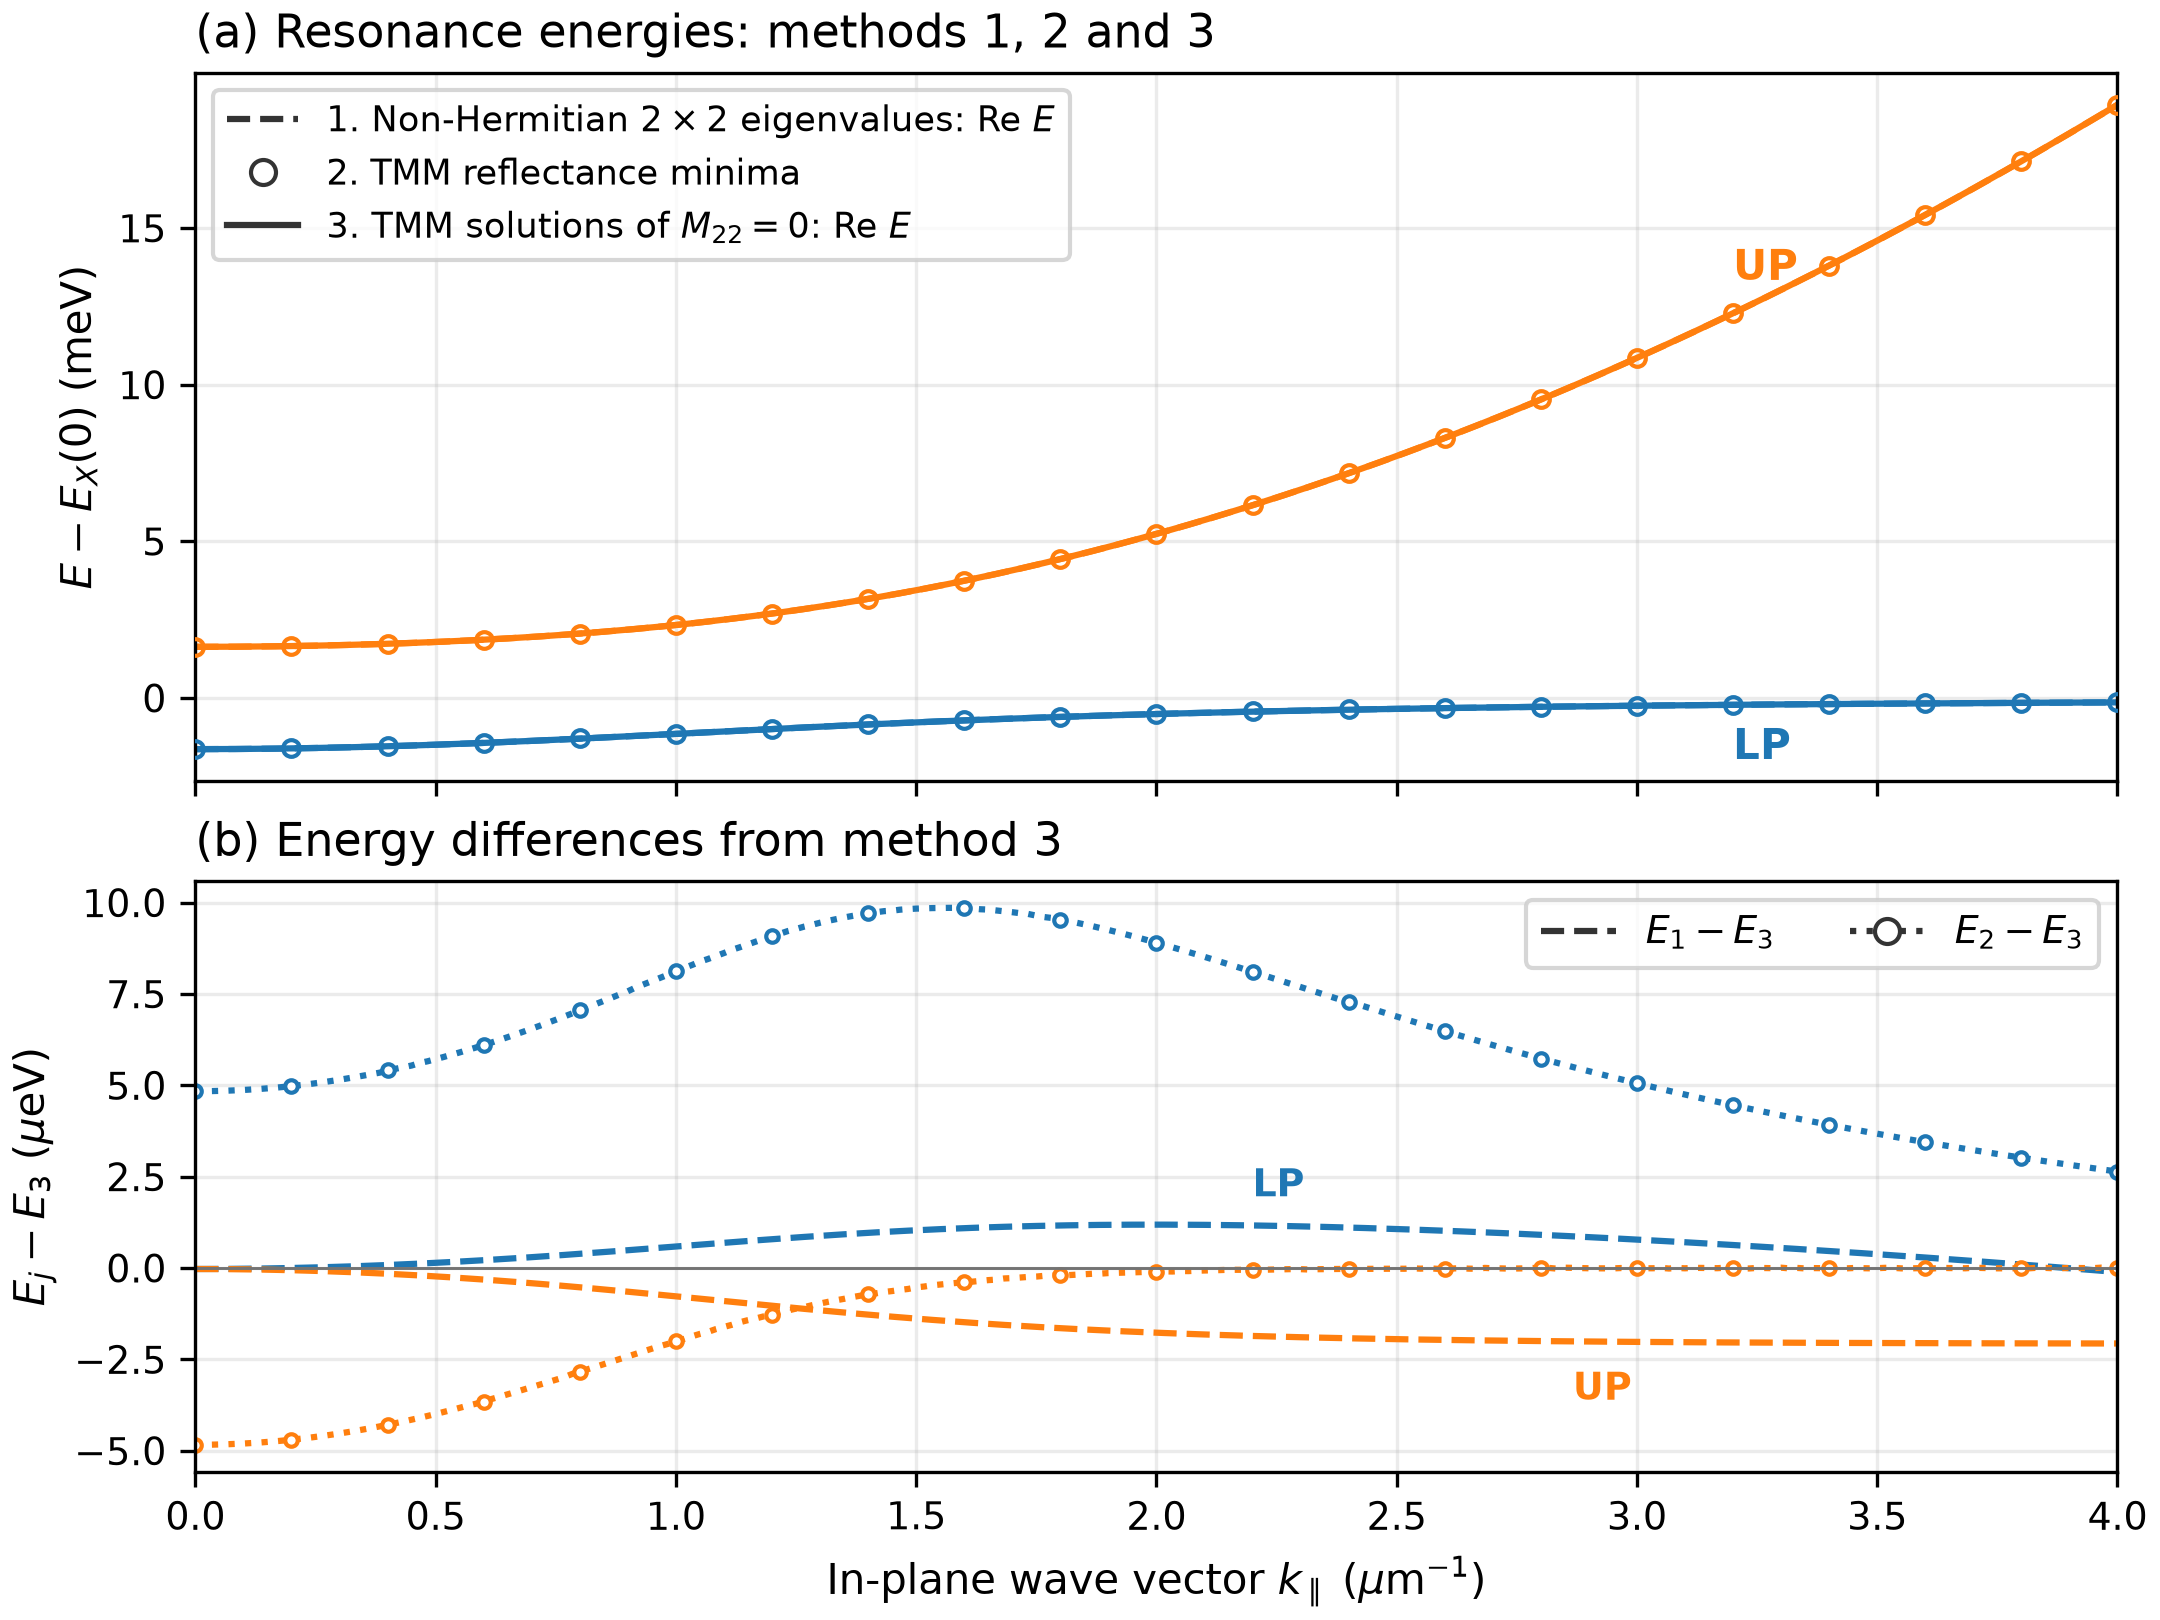

In [ ]:
# 15. Non-Hermitian eigenvalues versus full TMM poles at equal real k
from pathlib import Path
import json
import numpy as np
import microcavity as mc
from IPython.display import Image, display

LOAD_SAVED_COMPLEX_COMPARISON = False
if LOAD_SAVED_COMPLEX_COMPARISON:
    complex_comparison = mc.load_complex_comparison()
else:
    tmm_pole_pairs = np.column_stack((poles_te["lp"], poles_te["up"]))
    dip_pairs = np.column_stack((dips_te["lp"], dips_te["up"]))
    resolved_pairs = np.column_stack((dips_te["resolved_lp"], dips_te["resolved_up"]))
    complex_comparison = mc.compare_complex_modes(
        momentum_grid, bare_poles, exciton_grid, cfg["gamma_x"],
        cfg["single_qw_rabi_target"], tmm_pole_pairs, dip_pairs, resolved_pairs,
    )
    mc.validate_complex_comparison_poles(
        complex_comparison, background_layers, polariton_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    complex_comparison["provenance"] = {
        "config": cfg, "cavity_length_um": cavity_length,
        "qw_position_um": qw_position, "gamma_0_eV": float(gamma_0),
        "background_layers": background_layers, "active_layers": polariton_layers,
        "geometry_source": "Current notebook geometry; no retuning in the final comparison",
        "tmm_source": "Current full-TMM TE complex poles and resolved reflectivity minima",
    }
comparison_stats = complex_comparison["statistics"]
print("Parameters (eV):", json.dumps(complex_comparison["parameters"], indent=2))
print("Residual statistics (micro-eV):", json.dumps(comparison_stats, indent=2))
print("Analytic eigenvalue residual (eV):", complex_comparison["checks"]["analytic_pair_error_eV"])
for path in mc.export_complex_comparison(complex_comparison):
    display(Image(filename=str(path)))


## 10. Summary diagnostics


In [ ]:
summary = {
    "tuned_cavity_length_um": cavity_length,
    "qw_position_um": qw_position,
    "gamma_0_mev": mc.to_mev(gamma_0),
    "single_qw_splitting_mev": mc.to_mev(calibration["splitting"]),
    "bare_cavity_fwhm_mev": mc.to_mev(mc.linewidth_from_pole(bare_pole["pole"])),
    "bare_cavity_Q": mc.quality_factor_from_pole(bare_pole["pole"]),
    "six_qw_effective_splitting_mev": mc.to_mev(multiple_qw_results[-1]["splitting"]),
    "maximum_pole_residual": max(
        np.nanmax(poles_te["residual_lp"]), np.nanmax(poles_te["residual_up"]),
        np.nanmax(poles_tm["residual_lp"]), np.nanmax(poles_tm["residual_up"]),
    ),
    "complex_comparison_statistics_ueV": comparison_stats,
    "complex_comparison_parameters_eV": complex_comparison["parameters"],
    "machine_limited_pole_count": int(
        poles_te["machine_limited_lp"].sum() + poles_te["machine_limited_up"].sum()
        + poles_tm["machine_limited_lp"].sum() + poles_tm["machine_limited_up"].sum()
    ),
}
summary